In [1]:
from pathlib import Path
import math

import numpy as np
import pandas as pd
from astropy.io import fits
from matplotlib import pyplot as plt

ROOT = Path.cwd()
FITS_DIR = ROOT / "fits_ready"
FIGS_DIR = ROOT / "Imgs"
FIGS_DIR.mkdir(exist_ok=True)


In [2]:
# -------------------------------------------------------
# MUSE 30 Doradus Halpha datasets
# -------------------------------------------------------

BINS = tuple(range(6))

DATASET_PREFIX = "MUSE-30Dor-H"
SUFFIX = "-ivsv"

datasets = [
    {
        "instrument": "MUSE",
        "bin": bin_level,
        "line": "Halpha",
        "filename": f"{DATASET_PREFIX}-bin{bin_level}{SUFFIX}.fits",
        "label": rf"${2**bin_level}\times{2**bin_level}$",
    }
    for bin_level in BINS
]

pd.DataFrame(datasets)


,instrument,bin,line,filename,label
0,MUSE,0,Halpha,MUSE-30Dor-H-bin0-ivsv.fits,$1\times1$
1,MUSE,1,Halpha,MUSE-30Dor-H-bin1-ivsv.fits,$2\times2$
2,MUSE,2,Halpha,MUSE-30Dor-H-bin2-ivsv.fits,$4\times4$
3,MUSE,3,Halpha,MUSE-30Dor-H-bin3-ivsv.fits,$8\times8$
4,MUSE,4,Halpha,MUSE-30Dor-H-bin4-ivsv.fits,$16\times16$
5,MUSE,5,Halpha,MUSE-30Dor-H-bin5-ivsv.fits,$32\times32$


In [3]:
def load_velocity_dataset(entry):
    fits_path = FITS_DIR / entry["filename"]

    if not fits_path.exists():
        raise FileNotFoundError(f"Missing FITS file: {fits_path}")

    with fits.open(fits_path) as hdul:
        sb = hdul["MOM0"].data.astype(float)
        vv = hdul["MOM1"].data.astype(float)

    yy, xx = np.indices(vv.shape)

    df = pd.DataFrame({
        "X": xx.ravel(),
        "Y": yy.ravel(),
        "VV": vv.ravel(),
        "SB": sb.ravel(),
    })

    df = df.dropna(subset=["VV", "SB"])

    df["instrument"] = entry["instrument"]
    df["line"] = entry["line"]
    df["label"] = entry["label"]
    df["filename"] = entry["filename"]
    df["bin"] = entry["bin"]

    mean_v = df["VV"].mean()
    df["RV_centered"] = df["VV"] - mean_v

    raw = {
        "sb": sb,
        "vv": vv,
        "instrument": entry["instrument"],
        "line": entry["line"],
        "label": entry["label"],
        "filename": entry["filename"],
        "bin": entry["bin"],
    }

    return df, raw


In [4]:
processed_list = []
raw_data = {}

for entry in datasets:
    df, raw = load_velocity_dataset(entry)
    processed_list.append(df)

    key = (entry["line"], entry["instrument"], entry["bin"])
    raw_data[key] = raw

processed_data = pd.concat(processed_list, ignore_index=True)

print(f"Loaded {len(datasets)} MUSE 30 Doradus Halpha datasets")


Loaded 6 MUSE 30 Doradus Halpha datasets


In [5]:
processed_data.head()

,X,Y,VV,SB,instrument,line,label,filename,bin,RV_centered
0,306,0,271.013497,0.131409,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,5.453864
1,307,0,273.394009,0.126746,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,7.834376
2,308,0,276.240517,0.108470,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,10.680884
3,309,0,273.005903,0.104170,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,7.446270
4,310,0,272.423073,0.095146,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,6.863440


In [6]:
processed_data.groupby("bin")[["VV", "RV_centered", "SB"]].describe()


VV                                                              \
        count        mean         std         min         25%         50%   
bin                                                                         
0    363059.0  265.559633   15.899375   91.565124  253.588414  264.409625   
1     90373.0  265.532532   15.807515  219.884477  253.575224  264.367795   
2     22477.0  266.505976   23.320029  223.776876  253.634694  264.421955   
3      5566.0  268.722845   47.147769  225.504863  253.627929  264.480814   
4      1366.0  274.412869  110.455783  227.465437  253.522520  264.615704   
5       317.0  283.551410  244.463848  231.710144  254.038182  264.225271   

                             RV_centered                ...             \
            75%          max       count          mean  ...        75%   
bin                                                     ...              
0    276.422219   610.812809    363059.0 -7.213651e-14  ...  10.862586   
1    276.270920   334.170556     90373.0  1.807456e-14  ...  10.738388   
2    276.376310  1138.166682     22477.0  5.179309e-15  ...   9.870333   
3    276.525290  1176.670191      5566.0  3.268037e-15  ...   7.802445   
4    276.626155  2127.224925      1366.0  3.928271e-14  ...   2.213286   
5    275.513297  4134.620534       317.0 -3.442882e-14  ...  -8.038112   

                        SB                                                    \
             max     count      mean       std       min       25%       50%   
bin                                                                            
0     345.253177  363059.0  0.110686  0.100405  0.000054  0.037486  0.079233   
1      68.638025   90373.0  0.113076  0.102483  0.002012  0.038322  0.081004   
2     871.660706   22477.0  0.115690  0.104766  0.001891  0.039391  0.082700   
3     907.947347    5566.0  0.127330  0.114606  0.003307  0.043491  0.090438   
4    1852.812055    1366.0  0.183255  0.162130  0.005094  0.063603  0.130597   
5    3851.069124     317.0  0.244317  0.205934  0.007681  0.087067  0.181608   

                    
          75%  max  
bin                 
0    0.156739  1.0  
1    0.160327  1.0  
2    0.164292  1.0  
3    0.181257  1.0  
4    0.265011  1.0  
5    0.347403  1.0  

[6 rows x 24 columns]

In [7]:
processed_data

,X,Y,VV,SB,instrument,line,label,filename,bin,RV_centered
0,306,0,271.013497,0.131409,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,5.453864
1,307,0,273.394009,0.126746,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,7.834376
2,308,0,276.240517,0.108470,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,10.680884
3,309,0,273.005903,0.104170,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,7.446270
4,310,0,272.423073,0.095146,MUSE,Halpha,$1\times1$,MUSE-30Dor-H-bin0-ivsv.fits,0,6.863440
...,...,...,...,...,...,...,...,...,...,...
483153,15,18,276.211827,0.409287,MUSE,Halpha,$32\times32$,MUSE-30Dor-H-bin5-ivsv.fits,5,-7.339583
483154,16,18,273.390160,0.337284,MUSE,Halpha,$32\times32$,MUSE-30Dor-H-bin5-ivsv.fits,5,-10.161249
483155,17,18,274.493296,0.250828,MUSE,Halpha,$32\times32$,MUSE-30Dor-H-bin5-ivsv.fits,5,-9.058113
483156,7,19,4134.620534,0.036981,MUSE,Halpha,$32\times32$,MUSE-30Dor-H-bin5-ivsv.fits,5,3851.069124


In [8]:
# Convenient dictionary: one DataFrame per bin level
ha_muse = {
    bin_level: processed_data[
        processed_data["bin"] == bin_level
    ].copy()
    for bin_level in BINS
}

# Optional aliases, kept for compatibility with the original notebook
ha_muse_bin0 = ha_muse[0]
ha_muse_bin1 = ha_muse[1]
ha_muse_bin2 = ha_muse[2]
ha_muse_bin3 = ha_muse[3]
ha_muse_bin4 = ha_muse[4]
ha_muse_bin5 = ha_muse[5]


In [9]:
instrument_colors = {
    "MUSE": "black",
}

line_order = ["Halpha"]


## Surface brightness vs radial velocity

The following panels compare the complete H\(\alpha\) intensity–velocity distribution across spatial binning levels.


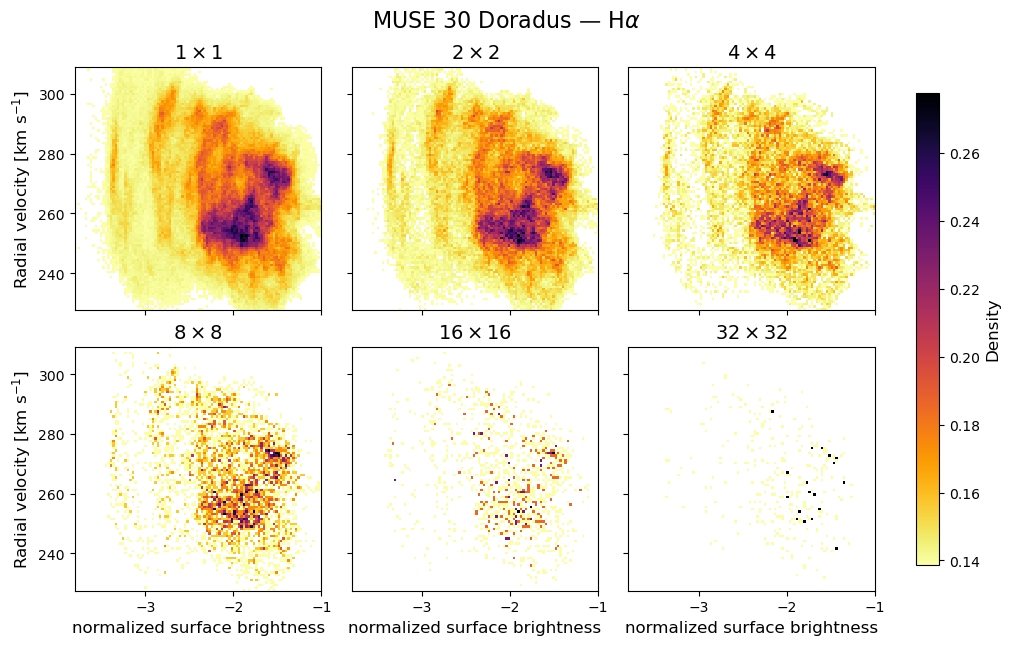

In [22]:
datasets_by_bin = ha_muse

bin_labels = {
    bin_level: rf"${2**bin_level}\times{2**bin_level}$"
    for bin_level in BINS
}

bin_order = list(BINS)

# Surface-brightness range is kept from the original diagnostic.
xrange = [-3.8, -1.0]

# Use one common radial-velocity range for all panels, derived from the
# complete 30 Dor sample. This avoids Orion-specific hard-coded limits.
v_lo, v_hi = np.nanpercentile(processed_data["VV"], [0.5, 99.5])
ypad = 0.05 * (v_hi - v_lo)
yrange = [v_lo - ypad, v_hi + ypad]

nbins_hist = 100

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(10, 6),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

axes = axes.flatten()
im = None

for ax, bin_id in zip(axes, bin_order):

    data = datasets_by_bin[bin_id]

    SB = np.asarray(data["SB"])
    VV = np.asarray(data["VV"])

    mask = (
        np.isfinite(SB)
        & np.isfinite(VV)
        & (SB > 0)
    )

    SB_valid = SB[mask]
    VV_valid = VV[mask]

    # Same normalization convention as the original notebook.
    SB_norm = SB_valid / (np.nanmedian(SB_valid) * 100)

    x = np.log10(SB_norm)
    y = VV_valid

    H, xedges, yedges = np.histogram2d(
        x,
        y,
        bins=nbins_hist,
        range=[xrange, yrange],
        density=True,
    )

    HH = np.where(H == 0, np.nan, H)

    im = ax.imshow(
        HH.T,
        origin="lower",
        aspect="auto",
        cmap="inferno_r",
        extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
        interpolation="nearest",
    )

    ax.set_title(bin_labels[bin_id], fontsize=14)
    ax.set_xlim(xrange)
    ax.set_ylim(yrange)
    ax.grid(False)

for idx, ax in enumerate(axes):
    row = idx // 3
    col = idx % 3

    if col == 0:
        ax.set_ylabel(
            r"Radial velocity [km s$^{-1}$]",
            fontsize=12,
        )

    if row == 1:
        ax.set_xlabel(
            r"normalized surface brightness",
            fontsize=12,
        )

cbar = fig.colorbar(
    im,
    ax=axes,
    shrink=0.9,
    pad=0.03,
)

fig.suptitle(
    r"MUSE 30 Doradus — H$\alpha$",
    fontsize=16,
    y=1.05,
)

cbar.set_label("Density", fontsize=12)

fig.savefig(
    FIGS_DIR / "MUSE_sb_vs_vv_bins.pdf",
    dpi=600,
    bbox_inches="tight",
)

plt.show()


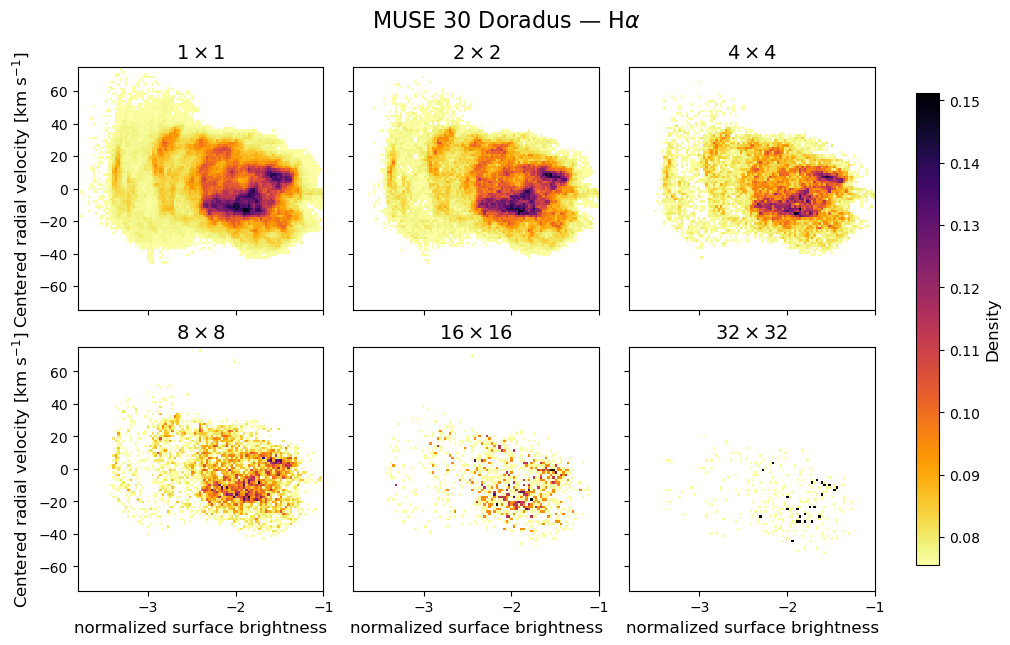

In [23]:
datasets_by_bin = ha_muse

bin_labels = {
    bin_level: rf"${2**bin_level}\times{2**bin_level}$"
    for bin_level in BINS
}

bin_order = list(BINS)

xrange = [-3.8, -1.0]

# Common centered-velocity range for all panels.
rv_lo, rv_hi = np.nanpercentile(processed_data["RV_centered"], [0.5, 99.5])
rv_span = max(abs(rv_lo), abs(rv_hi))
yrange = [-75, 75]

nbins_hist = 100

fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(10, 6),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

axes = axes.flatten()
im = None

for ax, bin_id in zip(axes, bin_order):

    data = datasets_by_bin[bin_id]

    SB = np.asarray(data["SB"])
    RV = np.asarray(data["RV_centered"])

    mask = (
        np.isfinite(SB)
        & np.isfinite(RV)
        & (SB > 0)
    )

    SB_valid = SB[mask]
    RV_valid = RV[mask]

    SB_norm = SB_valid / (np.nanmedian(SB_valid) * 100)

    x = np.log10(SB_norm)
    y = RV_valid

    H, xedges, yedges = np.histogram2d(
        x,
        y,
        bins=nbins_hist,
        range=[xrange, yrange],
        density=True,
    )

    HH = np.where(H == 0, np.nan, H)

    im = ax.imshow(
        HH.T,
        origin="lower",
        aspect="auto",
        cmap="inferno_r",
        extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]],
        interpolation="nearest",
    )

    ax.set_title(bin_labels[bin_id], fontsize=14)
    ax.set_xlim(xrange)
    ax.set_ylim(yrange)
    ax.grid(False)

for idx, ax in enumerate(axes):
    row = idx // 3
    col = idx % 3

    if col == 0:
        ax.set_ylabel(
            r"Centered radial velocity [km s$^{-1}$]",
            fontsize=12,
        )

    if row == 1:
        ax.set_xlabel(
            r"normalized surface brightness",
            fontsize=12,
        )

cbar = fig.colorbar(
    im,
    ax=axes,
    shrink=0.9,
    pad=0.03,
)

fig.suptitle(
    r"MUSE 30 Doradus — H$\alpha$",
    fontsize=16,
    y=1.05,
)

cbar.set_label("Density", fontsize=12)

fig.savefig(
    FIGS_DIR / "MUSE_sb_vs_centered_vv_bins.pdf",
    dpi=600,
    bbox_inches="tight",
)

plt.show()
